# 02 · Preparación, entrenamiento y evaluación del modelo (T-009 a T-012)
**Scoring predictivo de admisión de consultas — Carna, Mango & Asoc.**

> **Advertencia.** Todas las métricas de este notebook corresponden a una **validación sobre datos simulados** y no sobre casos reales del estudio (HU-008 AC3). Miden qué tan bien el modelo recupera los supuestos incorporados en la simulación, no su capacidad predictiva sobre decisiones reales de admisión.

Flujo offline (Diagrama de Arquitectura): encoding → split estratificado → entrenamiento XGBoost → evaluación → explicabilidad → serialización. La app Streamlit solo carga el artefacto resultante; nunca reentrena.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", message="IProgress not found")
import json, hashlib
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, shap, xgboost, sklearn
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, RocCurveDisplay)
from src.features import load_dataset, build_features, build_target, MODEL_COLUMNS
from src.constants import DOMAINS, NATURAL_LABELS

BLUE, RED, GREY = "#2a78d6", "#e34948", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
SEED = 42
print("xgboost", xgboost.__version__, "| shap", shap.__version__, "| scikit-learn", sklearn.__version__)

xgboost 3.4.1 | shap 0.54.1 | scikit-learn 1.8.0


## 1. Encoding de variables (T-009)
`build_features` (en `src/features.py`, compartido con la app para evitar *train/serve skew*):
- **Nominales** (`canal_ingreso`, `area_practica`, `tipo_reclamo`, `jurisdiccion`) → `pd.Categorical` con las categorías **fijas** de `DOMAINS`, consumidas por el soporte categórico nativo de XGBoost (`enable_categorical=True`) en lugar de one-hot.
- **Ordinales** (`estado_prescripcion`, `documentacion_aportada`) → enteros según su orden.
- **`monto_estimado`** → se deja el `NaN` (XGBoost aprende la dirección por defecto) + bandera `monto_informado`.
- No se escala: los árboles son invariantes a transformaciones monótonas.

In [2]:
df = load_dataset()
X = build_features(df, DOMAINS)
y = build_target(df)
assert "resultado_final_caso" not in X.columns
print(X.shape, "| tasa positiva:", round(y.mean(), 3))
X.head()

(1224, 8) | tasa positiva: 0.583


,canal_ingreso,area_practica,tipo_reclamo,jurisdiccion,estado_prescripcion,documentacion_aportada,monto_estimado,monto_informado
0,Referido,Civil,Cobro de deuda,Provincia de Buenos Aires,1.0,2.0,4410000.0,1
1,Referido,Consumidor,Daños por producto defectuoso,CABA,2.0,0.0,2250000.0,1
2,Teléfono,Laboral,Horas extras impagas,CABA,1.0,1.0,1920000.0,1
3,Referido,Laboral,Créditos laborales por acoso,Provincia de Buenos Aires,1.0,1.0,NaN,0
4,Formulario web,Civil,Cobro de deuda,Provincia de Buenos Aires,1.0,2.0,1260000.0,1


## 2. Separación entrenamiento / evaluación (T-010)
80/20 estratificado por la variable objetivo, semilla fija para reproducibilidad.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"Entrenamiento: {len(X_train)} ({y_train.mean():.1%} aceptadas) · Evaluación: {len(X_test)} ({y_test.mean():.1%} aceptadas)")

Entrenamiento: 979 (58.2% aceptadas) · Evaluación: 245 (58.4% aceptadas)


## 3. Entrenamiento XGBoost (T-011)
Punto de partida: una configuración inicial conservadora (`max_depth=4`, `n_estimators=300`, `learning_rate=0.05`), conservadora para un dataset chico. Como 1224 filas dejan poco margen, se ajustan profundidad, cantidad de árboles y *learning rate* con una búsqueda en grilla y validación cruzada estratificada de 5 particiones (métrica: AUC-ROC), **solo sobre el conjunto de entrenamiento**. El conjunto de evaluación no se usa hasta la sección 4.

In [4]:
from sklearn.model_selection import GridSearchCV
BASE = dict(subsample=0.8, colsample_bytree=0.8, enable_categorical=True, tree_method="hist",
            eval_metric="logloss", random_state=SEED)
GRID = {"max_depth": [2, 3, 4], "n_estimators": [100, 200, 300], "learning_rate": [0.03, 0.05, 0.1]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(XGBClassifier(**BASE), GRID, cv=cv, scoring="roc_auc", n_jobs=1).fit(X_train, y_train)

res = pd.DataFrame(search.cv_results_)
cols = ["param_max_depth", "param_n_estimators", "param_learning_rate", "mean_test_score", "std_test_score"]
initial = res[(res.param_max_depth == 4) & (res.param_n_estimators == 300) & (res.param_learning_rate == 0.05)]
print(f"AUC CV configuración inicial (4/300/0.05): {initial.mean_test_score.iloc[0]:.3f}")
print(f"AUC CV mejor configuración: {search.best_score_:.3f} -> {search.best_params_}")
res.sort_values("mean_test_score", ascending=False)[cols].head(8).round(4)

AUC CV configuración inicial (4/300/0.05): 0.818
AUC CV mejor configuración: 0.844 -> {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}


,param_max_depth,param_n_estimators,param_learning_rate,mean_test_score,std_test_score
18,2,100,0.10,0.8438,0.0230
1,2,200,0.03,0.8427,0.0254
0,2,100,0.03,0.8423,0.0276
10,2,200,0.05,0.8418,0.0264
9,2,100,0.05,0.8410,0.0251
2,2,300,0.03,0.8409,0.0263
11,2,300,0.05,0.8399,0.0261
12,3,100,0.05,0.8390,0.0277


Los árboles poco profundos generalizan mejor: es consistente con que la simulación se generó a partir de reglas simples (exclusiones automáticas + efecto principal de la documentación), con pocas interacciones de orden alto que justifiquen árboles más profundos.

In [5]:
PARAMS = {**BASE, **search.best_params_}
for metric in ["accuracy", "f1", "roc_auc"]:
    s = cross_val_score(XGBClassifier(**PARAMS), X_train, y_train, cv=cv, scoring=metric)
    print(f"CV {metric:9s}: {s.mean():.3f} ± {s.std():.3f}")

CV accuracy : 0.819 ± 0.019


CV f1       : 0.860 ± 0.013


CV roc_auc  : 0.844 ± 0.023


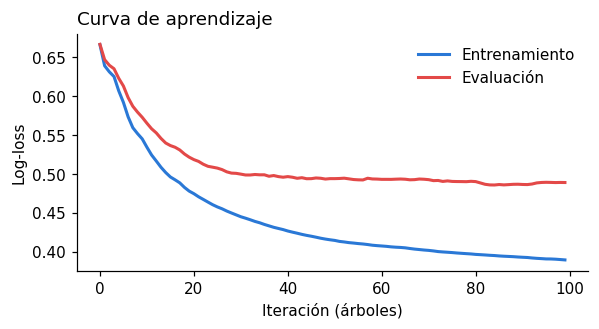

In [6]:
model = XGBClassifier(**PARAMS)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
history = model.evals_result()
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(history["validation_0"]["logloss"], color=BLUE, lw=2, label="Entrenamiento")
ax.plot(history["validation_1"]["logloss"], color=RED, lw=2, label="Evaluación")
ax.set_xlabel("Iteración (árboles)"); ax.set_ylabel("Log-loss"); ax.legend(frameon=False)
ax.set_title("Curva de aprendizaje", loc="left"); plt.show()

## 4. Evaluación sobre el conjunto de evaluación (T-012 · HU-008)
Se reportan exactitud, precisión, recall, F1 (AC1), la matriz de confusión (AC2) y, por lo anticipado en el Marco Teórico, el AUC-ROC. Se compara contra dos referencias: el clasificador trivial (siempre "Aceptada") y una regresión logística con one-hot encoding, la alternativa más simple descartada en el Marco Teórico.

In [7]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1_score": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
}
conf_matrix = confusion_matrix(y_test, y_pred)
pd.Series(metrics).round(3).to_frame("XGBoost — evaluación (datos simulados)")

,XGBoost — evaluación (datos simulados)
accuracy,0.788
precision,0.757
recall,0.937
f1_score,0.838
roc_auc,0.816


              precision    recall  f1-score   support

   Rechazada      0.868     0.578     0.694       102
    Aceptada      0.757     0.937     0.838       143

    accuracy                          0.788       245
   macro avg      0.812     0.758     0.766       245
weighted avg      0.803     0.788     0.778       245



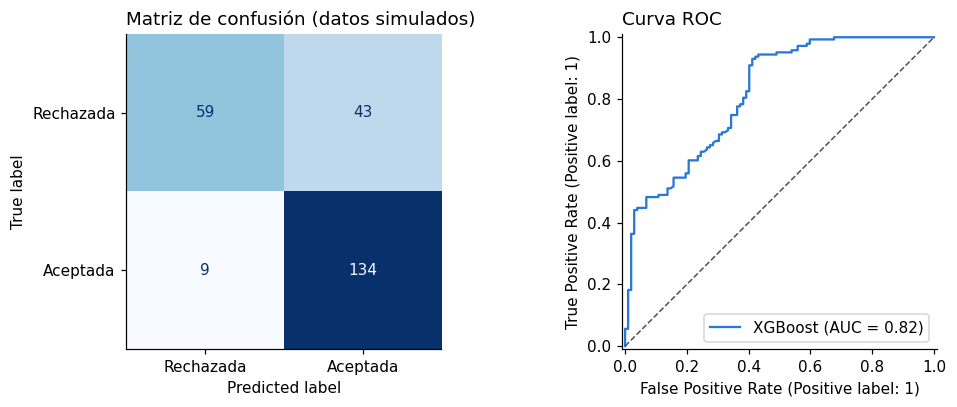

In [8]:
print(classification_report(y_test, y_pred, target_names=["Rechazada", "Aceptada"], digits=3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ConfusionMatrixDisplay(conf_matrix, display_labels=["Rechazada", "Aceptada"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (datos simulados)", loc="left")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name="XGBoost", curve_kwargs={"color": BLUE})
axes[1].plot([0, 1], [0, 1], ls="--", color=GREY, lw=1); axes[1].set_title("Curva ROC", loc="left")
plt.tight_layout(); plt.show()

### Comparación con alternativas

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

nominal = ["canal_ingreso", "area_practica", "tipo_reclamo", "jurisdiccion"]
numeric = ["estado_prescripcion", "documentacion_aportada", "monto_estimado", "monto_informado"]
logreg = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), nominal),
                       ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric)]),
    LogisticRegression(max_iter=1000))
logreg.fit(X_train.astype({c: str for c in nominal}), y_train)
p_lr = logreg.predict_proba(X_test.astype({c: str for c in nominal}))[:, 1]

def summarize(y_true, proba):
    pred = (proba >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "f1_score": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba) if proba.std() > 0 else 0.5}

comparison = pd.DataFrame({
    "Trivial (siempre Aceptada)": summarize(y_test, np.ones(len(y_test))),
    "Regresión logística": summarize(y_test, p_lr),
    "XGBoost": summarize(y_test, y_proba),
}).T.round(3)
comparison

,accuracy,precision,recall,f1_score,roc_auc
Trivial (siempre Aceptada),0.584,0.584,1.000,0.737,0.500
Regresión logística,0.788,0.786,0.874,0.828,0.820
XGBoost,0.788,0.757,0.937,0.838,0.816


**Lectura.** XGBoost supera ampliamente al clasificador trivial. Frente a la regresión logística el desempeño es similar: esperable, porque la simulación se generó con reglas relativamente simples (exclusiones + efecto principal de la documentación) que un modelo lineal también captura. La elección de XGBoost se sostiene por los criterios ya fundamentados en el Marco Teórico (capacidad de capturar no linealidades e interacciones sin especificarlas a priori, sobre un dominio cuya forma funcional real se desconoce, e integración madura con SHAP), no por una ventaja de desempeño sobre estos datos simulados. Las métricas obtenidas **no** deben interpretarse como capacidad predictiva sobre consultas reales.

## 5. Explicabilidad global con SHAP (T-014)
Se usa `shap.TreeExplainer` (TreeSHAP exacto, Lundberg & Lee, 2017). Las contribuciones están en escala log-odds: valores positivos empujan hacia "Aceptada" y negativos hacia "Rechazada". La revisión de la importancia global sirve, además, como control del riesgo R2 (detectar relaciones espurias heredadas de la simulación).

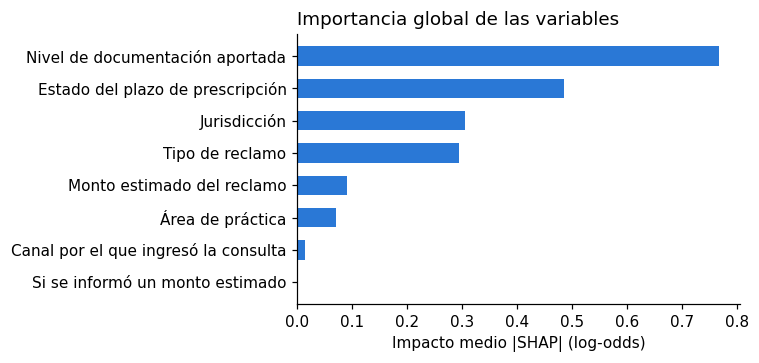

In [10]:
explainer = shap.TreeExplainer(model)
shap_test = explainer.shap_values(X_test)
importance = (pd.Series(np.abs(shap_test).mean(axis=0), index=X_test.columns)
               .rename(NATURAL_LABELS).sort_values())
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set_xlabel("Impacto medio |SHAP| (log-odds)"); ax.set_title("Importancia global de las variables", loc="left")
plt.tight_layout(); plt.show()

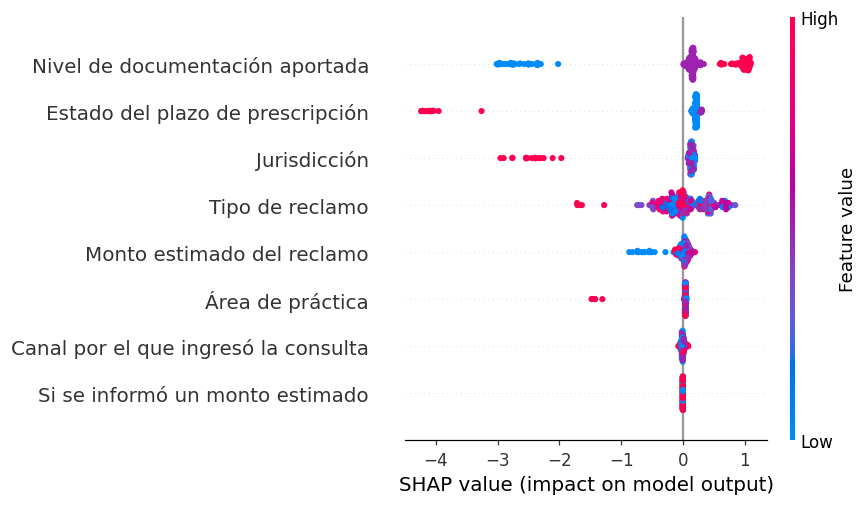

In [11]:
shap.summary_plot(shap_test, X_test.assign(**{c: X_test[c].cat.codes for c in nominal}),
                  feature_names=[NATURAL_LABELS[c] for c in X_test.columns], show=True)

### Ejemplo de explicación individual (lo que verá el socio en la Pantalla 2)

In [12]:
row = X_test.iloc[[0]]
print(df.loc[row.index[0], ["tipo_reclamo", "documentacion_aportada", "estado_prescripcion", "resultado_admision"]].to_dict())
print(f"Puntaje: {model.predict_proba(row)[0, 1]*100:.0f}%")
contributions = sorted(zip(row.columns, explainer.shap_values(row)[0]), key=lambda t: -abs(t[1]))
pd.DataFrame([{"variable": NATURAL_LABELS[c], "contribucion": round(float(v), 4),
               "sentido": "positivo" if v > 0 else "negativo"} for c, v in contributions])

{'tipo_reclamo': 'Horas extras impagas', 'documentacion_aportada': 'Ninguna', 'estado_prescripcion': 'Vigente', 'resultado_admision': 'Rechazada'}
Puntaje: 2%


,variable,contribucion,sentido
0,Nivel de documentación aportada,-2.5093,negativo
1,Jurisdicción,-2.3277,negativo
2,Estado del plazo de prescripción,0.1396,positivo
3,Tipo de reclamo,0.1364,positivo
4,Monto estimado del reclamo,0.0698,positivo
5,Área de práctica,0.0229,positivo
6,Canal por el que ingresó la consulta,-0.0116,negativo
7,Si se informó un monto estimado,0.0000,negativo


## 6. Serialización (fin del flujo offline)
Se versionan en el repositorio: el modelo (`.joblib`), los dominios usados para el encoding (`domains.json`) y la metadata del entrenamiento (`metadata.json`: versión, métricas, versiones de librerías). La app lee `metadata.json` para saber qué artefacto cargar, y `version_modelo` se guarda en cada registro de la tabla `prediccion`.

In [13]:
model_dir = ROOT / "model"; model_dir.mkdir(exist_ok=True)
today = date.today().isoformat()
model_file = f"xgb_admision_v1_{today}.joblib"
for old in model_dir.glob("xgb_admision_v1_*.joblib"):
    old.unlink()
joblib.dump(model, model_dir / model_file)
(model_dir / "domains.json").write_text(json.dumps(DOMAINS, ensure_ascii=False, indent=2), encoding="utf-8")
metadata = {
    "model_version": f"xgb_v1_{today}",
    "model_file": model_file,
    "trained_on": today,
    "model_sha256": hashlib.sha256((model_dir / model_file).read_bytes()).hexdigest()[:16],
    "dataset": "Carna_Dataset_Simulado.xlsx (hoja Consultas, 1224 filas, 100% simulado)",
    "features": MODEL_COLUMNS,
    "hyperparameters": {k: v for k, v in PARAMS.items()},
    "split": {"test_size": 0.2, "random_state": SEED, "stratify": True,
              "n_train": int(len(X_train)), "n_test": int(len(X_test))},
    "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "conf_matrix": {"labels": ["Rechazada", "Aceptada"], "values": conf_matrix.tolist()},
    "comparison": comparison.to_dict(orient="index"),
    "global_importance": importance.sort_values(ascending=False).round(4).to_dict(),
    "warning": "Métricas obtenidas sobre datos simulados; no representan desempeño sobre casos reales.",
    "versions": {"xgboost": xgboost.__version__, "shap": shap.__version__, "scikit-learn": sklearn.__version__},
}
(model_dir / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Guardado:", model_file); metadata["test_metrics"]

Guardado: xgb_admision_v1_2026-11-03.joblib


{'accuracy': 0.7878,
 'precision': 0.7571,
 'recall': 0.9371,
 'f1_score': 0.8375,
 'roc_auc': 0.8163}

In [14]:
# Verificación: el artefacto serializado reproduce exactamente las predicciones
reloaded = joblib.load(model_dir / model_file)
assert np.allclose(reloaded.predict_proba(X_test), model.predict_proba(X_test))
print("OK: el model reloaded reproduce las predicciones.")

OK: el model reloaded reproduce las predicciones.
